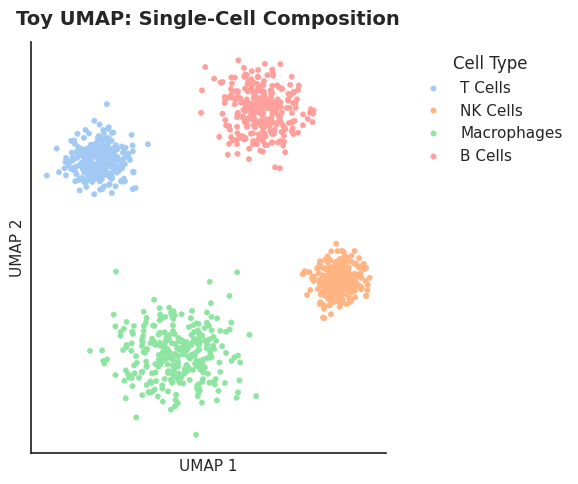

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs

# 1. Generate toy clusters (simulating low-dimensional UMAP space coordinates)
X, y = make_blobs(
    n_samples=1200, 
    centers=[(-4, 3), (2, 5), (5, -2), (-1, -5)],  # Cluster centers
    cluster_std=[0.6, 0.8, 0.5, 1.1],              # Tightness of each cell type
    random_state=42
)

# 2. Map cluster IDs to realistic cell types
cell_type_mapping = {
    0: "T Cells",
    1: "B Cells",
    2: "NK Cells",
    3: "Macrophages"
}
cell_types = [cell_type_mapping[label] for label in y]

# 3. Create DataFrame
df = pd.DataFrame(X, columns=["UMAP_1", "UMAP_2"])
df["Cell Type"] = cell_types

# 4. Plot the publication-ready figure
plt.figure(figsize=(6, 5))
sns.set_theme(style="white")

# Plot points with a clean, standard palette (e.g., 'Set2', 'tab10')
ax = sns.scatterplot(
    data=df, 
    x="UMAP_1", 
    y="UMAP_2", 
    hue="Cell Type", 
    palette="pastel", 
    s=15,          # Point size
    alpha=1,     # Point transparency
    edgecolor=None # Remove outlines for a cleaner look
)

# Format to mimic typical single-cell software (like Seurat or Scanpy)
ax.set_title("Toy UMAP: Single-Cell Composition", fontsize=14, pad=12, weight="bold")
ax.set_xlabel("UMAP 1", fontsize=11)
ax.set_ylabel("UMAP 2", fontsize=11)
sns.despine() # Remove top and right borders

# Tidy up the axes ticks (common in schematic diagrams)
ax.set_xticks([])
ax.set_yticks([])

# Position the legend cleanly outside or to the side
plt.legend(title="Cell Type", bbox_to_anchor=(1.05, 1), loc="upper left", frameon=False)
plt.tight_layout()
plt.show()
